

## ***Caricamento dell'immagine e primo preprocessing***


Saving Si-Au_pillar_024.tif to Si-Au_pillar_024.tif
File: Si-Au_pillar_024.tif
Dimensioni: 1024 × 943 pixel
Tipo dati originale: uint16
Visualizzazione delle immagini:
Immagine originale: (943, 1024), tipo: uint16
ROI ritagliata: (872, 1024)
Immagine normalizzata: (872, 1024), tipo: float32


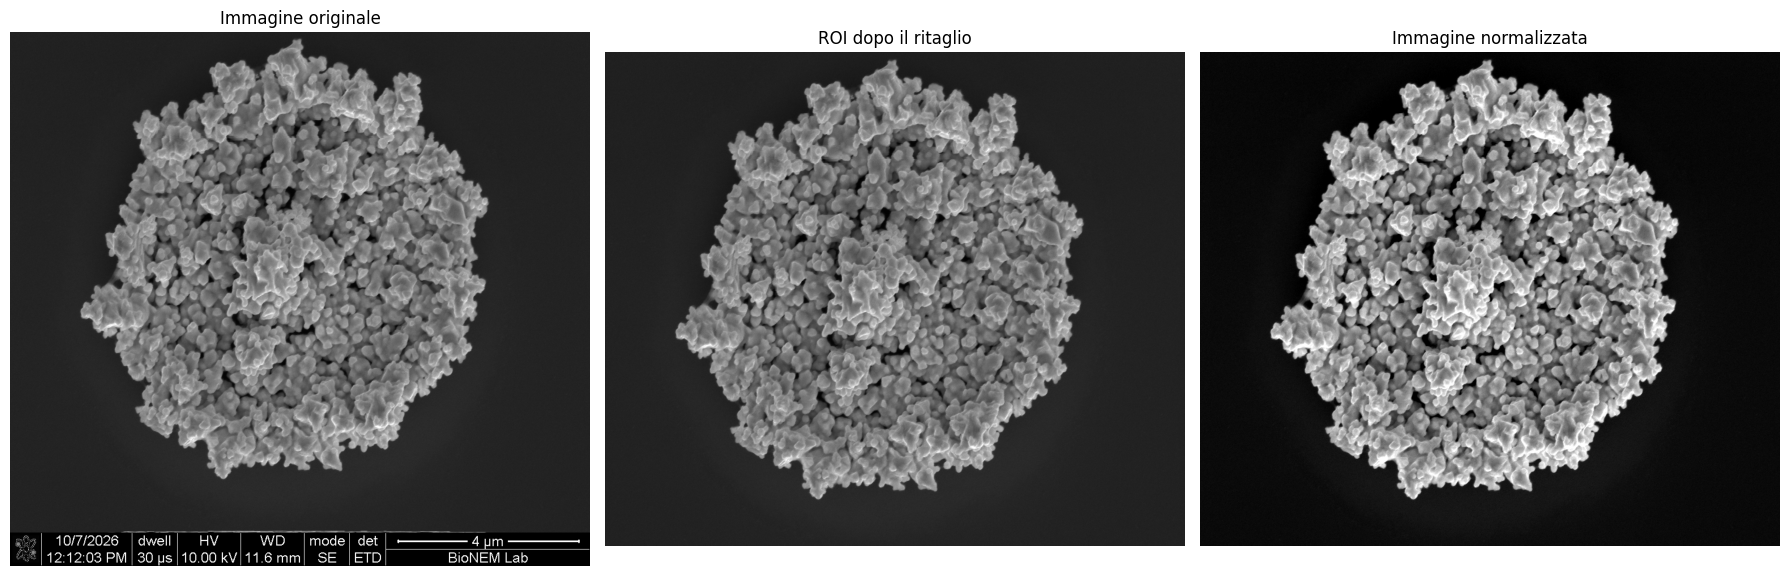

In [2]:
!pip -q install numpy scipy opencv-python tifffile pandas matplotlib scikit-image
import io
import os
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from google.colab import files
from scipy import ndimage as ndi
from skimage import exposure, filters, feature, morphology, segmentation, measure, color, util



# ----------------------- 1. CARICAMENTO TIFF -----------------------

uploaded = files.upload()



if not uploaded:

        raise RuntimeError("Nessun file caricato.")



tiff_names = [

        name for name in uploaded.keys()

        if name.lower().endswith((".tif", ".tiff"))

]

if not tiff_names:

        raise ValueError(

                "Non è stato trovato un file .tif/.tiff. "

                f"File ricevuti: {list(uploaded.keys())}"

        )



# Seleziona il primo TIFF, non un eventuale file JSON o di configurazione.

filename = tiff_names[0]

file_bytes = uploaded[filename]



# Verifica l'intestazione TIFF prima di leggere: evita il precedente errore JSON.

if not (file_bytes[:4] in (b"II*\x00", b"MM\x00*", b"II+\x00", b"MM\x00+")):

        raise ValueError(

                f"'{filename}' non sembra un TIFF valido: intestazione {file_bytes[:8]!r}. "

                "Seleziona il file originale .tif/.tiff, non un JSON o un file di testo."

        )



image_raw = tifffile.imread(io.BytesIO(file_bytes))



# Converti RGB/RGBA in grigio se necessario.

if image_raw.ndim == 3 and image_raw.shape[-1] in (3, 4):

        rgb = image_raw[..., :3]

        image_raw = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

elif image_raw.ndim == 3:

        # Se è una pila di immagini, usa il primo piano per questa pipeline 2D.

        print("Nota: TIFF multipagina/stack rilevato; per questa analisi uso il primo piano.")

        image_raw = image_raw[0]



if image_raw.ndim != 2:

        raise ValueError(f"Immagine non 2D dopo la conversione: shape={image_raw.shape}")



print(f"File: {filename}")

print(f"Dimensioni: {image_raw.shape[1]} × {image_raw.shape[0]} pixel")

print(f"Tipo dati originale: {image_raw.dtype}")



# ----------------------- 2. CARTELLA OUTPUT -----------------------

OUT = Path("/content/risultati_SEM_watershed")

OUT.mkdir(parents=True, exist_ok=True)



# ----------------------- 3. ROI E NORMALIZZAZIONE -----------------------

# Esclude la fascia inferiore con barra/metadata. Impostare 0 se già ritagliata.

CROP_BOTTOM = 0.075

h0, w0 = image_raw.shape

h = max(1, int(h0 * (1 - CROP_BOTTOM)))

raw_roi = image_raw[:h, :]



# Normalizzazione robusta, preservando il file originale.

raw_float = raw_roi.astype(np.float32)

lo, hi = np.percentile(raw_float, (1, 99.5))

if hi <= lo:

        raise ValueError("Intervallo di intensità insufficiente nell'immagine.")

gray = np.clip((raw_float - lo) / (hi - lo), 0, 1).astype(np.float32)


#print dell'immagine
# ----------------------- 4. VISUALIZZAZIONE IMMAGINI -----------------------

print("Visualizzazione delle immagini:")
print(f"Immagine originale: {image_raw.shape}, tipo: {image_raw.dtype}")
print(f"ROI ritagliata: {raw_roi.shape}")
print(f"Immagine normalizzata: {gray.shape}, tipo: {gray.dtype}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image_raw, cmap="gray")
axes[0].set_title("Immagine originale")
axes[0].axis("off")

axes[1].imshow(raw_roi, cmap="gray")
axes[1].set_title("ROI dopo il ritaglio")
axes[1].axis("off")

axes[2].imshow(gray, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Immagine normalizzata")
axes[2].axis("off")

plt.tight_layout()
plt.show()


# ***Denoising dell'immagine (filtro gaussiano) + correzione del fondo***


Visualizzazione dei risultati del pre-processing:
Immagine normalizzata: (872, 1024)
Immagine denoised: (872, 1024)
Immagine corretta: (872, 1024)


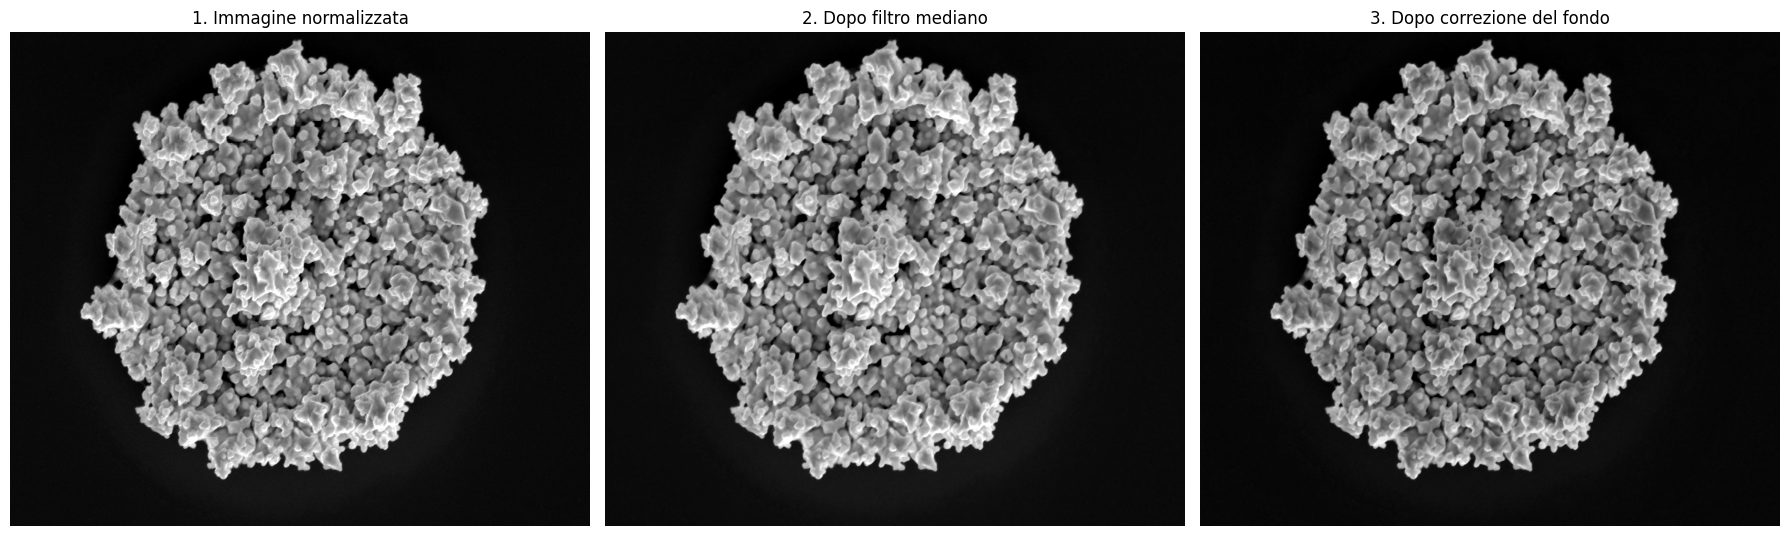

In [35]:
# ----------------------- 4. DENOISING LEGGERO -----------------------

# Filtro mediano su uint8 per attenuare rumore puntiforme.

gray8 = np.round(gray * 255).astype(np.uint8)

denoised8 = cv2.medianBlur(gray8, 3)

denoised = denoised8.astype(np.float32) / 255.0



# ----------------------- 5. CORREZIONE DEL FONDO -----------------------

# Stima sfondo con apertura morfologica ampia; sottrazione soft, non aggressiva.

# Il raggio è scalabile e può essere regolato in base alla dimensione dei cristalli.

background_radius = max(15, int(round(min(gray.shape) * 0.035)))

kernel_size = 2 * background_radius + 1

kernel = cv2.getStructuringElement(

        cv2.MORPH_ELLIPSE, (kernel_size, kernel_size)

)

background8 = cv2.morphologyEx(

        denoised8, cv2.MORPH_OPEN, kernel, iterations=1

)

background = background8.astype(np.float32) / 255.0



# Correzione delicata per evitare che le ombre reali vengano cancellate.

corrected = np.clip(denoised - 0.35 * background, 0, 1)

corrected = exposure.rescale_intensity(corrected, in_range="image", out_range=(0, 1))

# ----------------------- 6. VISUALIZZAZIONE DENOISING E FONDO -----------------------

print("Visualizzazione dei risultati del pre-processing:")
print(f"Immagine normalizzata: {gray.shape}")
print(f"Immagine denoised: {denoised.shape}")
print(f"Immagine corretta: {corrected.shape}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(gray, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("1. Immagine normalizzata")
axes[0].axis("off")

axes[1].imshow(denoised, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("2. Dopo filtro mediano")
axes[1].axis("off")

axes[2].imshow(corrected, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("3. Dopo correzione del fondo")
axes[2].axis("off")

plt.tight_layout()
plt.show()


# ***Miglioramento del contrasto locale***

Visualizzazione del contrasto locale:
Immagine prima del CLAHE: (872, 1024)
Immagine dopo il CLAHE: (872, 1024)


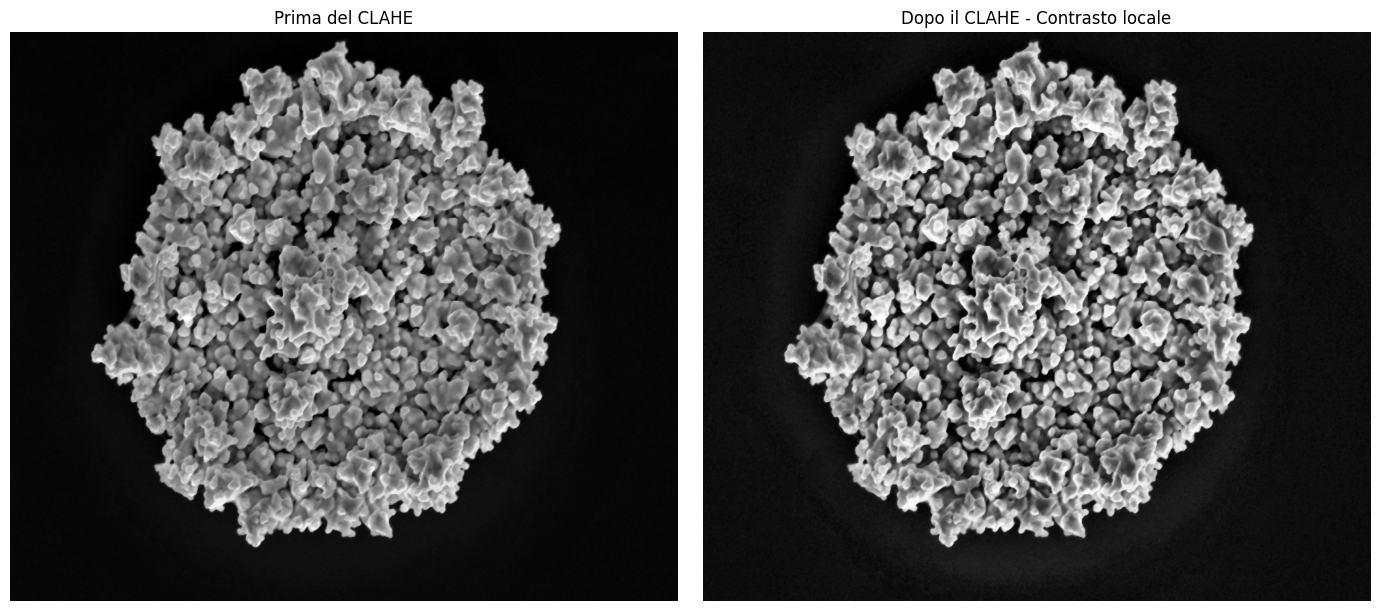

In [4]:
# ----------------------- 6. CONTRASTO LOCALE -----------------------

clahe = cv2.createCLAHE(clipLimit=1.6, tileGridSize=(8, 8))

enhanced8 = clahe.apply(np.round(corrected * 255).astype(np.uint8))

enhanced = enhanced8.astype(np.float32) / 255.0

# ----------------------- 7. VISUALIZZAZIONE CONTRASTO LOCALE -----------------------

print("Visualizzazione del contrasto locale:")
print(f"Immagine prima del CLAHE: {corrected.shape}")
print(f"Immagine dopo il CLAHE: {enhanced.shape}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(corrected, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Prima del CLAHE")
axes[0].axis("off")

axes[1].imshow(enhanced, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Dopo il CLAHE - Contrasto locale")
axes[1].axis("off")

plt.tight_layout()
plt.show()


# ***Creazione aschera binaria mendiante thresholding (OTSU)***

Soglia Otsu: 0.3638
Copertura della maschera: 30.87%
Pixel classificati come particella: 275676
Dimensioni della maschera: (872, 1024)


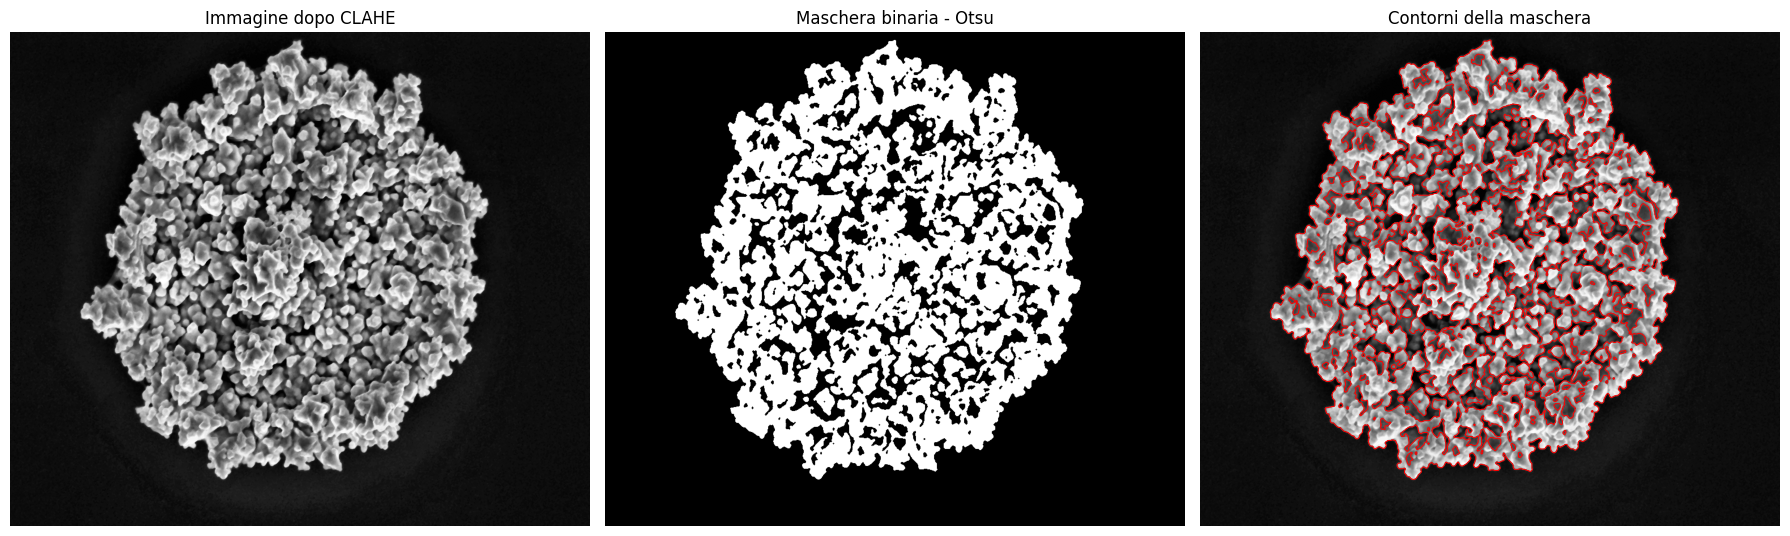

In [5]:
# ----------------------- 8. MASCHERA INIZIALE CON OTSU -----------------------

# Sogliatura globale di Otsu sull'immagine enhanced
threshold = filters.threshold_otsu(enhanced)
initial_mask = enhanced > threshold

# Esclude lo sfondo nero
initial_mask = initial_mask & (gray > 0.03)

# Pulizia della maschera
initial_mask = morphology.remove_small_objects(
    initial_mask.astype(bool),
    min_size=35
)

initial_mask = morphology.binary_opening(
    initial_mask,
    morphology.disk(1)
)

initial_mask = morphology.binary_closing(
    initial_mask,
    morphology.disk(1)
)

# Calcolo della copertura
coverage = float(initial_mask.mean())

print(f"Soglia Otsu: {threshold:.4f}")
print(f"Copertura della maschera: {coverage:.2%}")
print(f"Pixel classificati come particella: {np.count_nonzero(initial_mask)}")
print(f"Dimensioni della maschera: {initial_mask.shape}")

# ----------------------- 9. VISUALIZZAZIONE -----------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(enhanced, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Immagine dopo CLAHE")
axes[0].axis("off")

axes[1].imshow(initial_mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Maschera binaria - Otsu")
axes[1].axis("off")

axes[2].imshow(enhanced, cmap="gray", vmin=0, vmax=1)
axes[2].contour(
    initial_mask,
    levels=[0.5],
    colors="red",
    linewidths=0.7
)
axes[2].set_title("Contorni della maschera")
axes[2].axis("off")

plt.tight_layout()
plt.show()


# ***Calcolo della "Distance Transform:"***
La distance transform calcola, per ogni pixel bianco della maschera la distanza dal pixel nero più vicino.

Si prendono poi i massimi che corrispondono al centro delle particelle
e che saranno poi i marker iniziali da cui fare il watershed.


Numero di massimi locali trovati: 454
Numero di marker generati: 454
Dimensioni della distance transform: (872, 1024)
Valore massimo della distance transform: 23.71 pixel


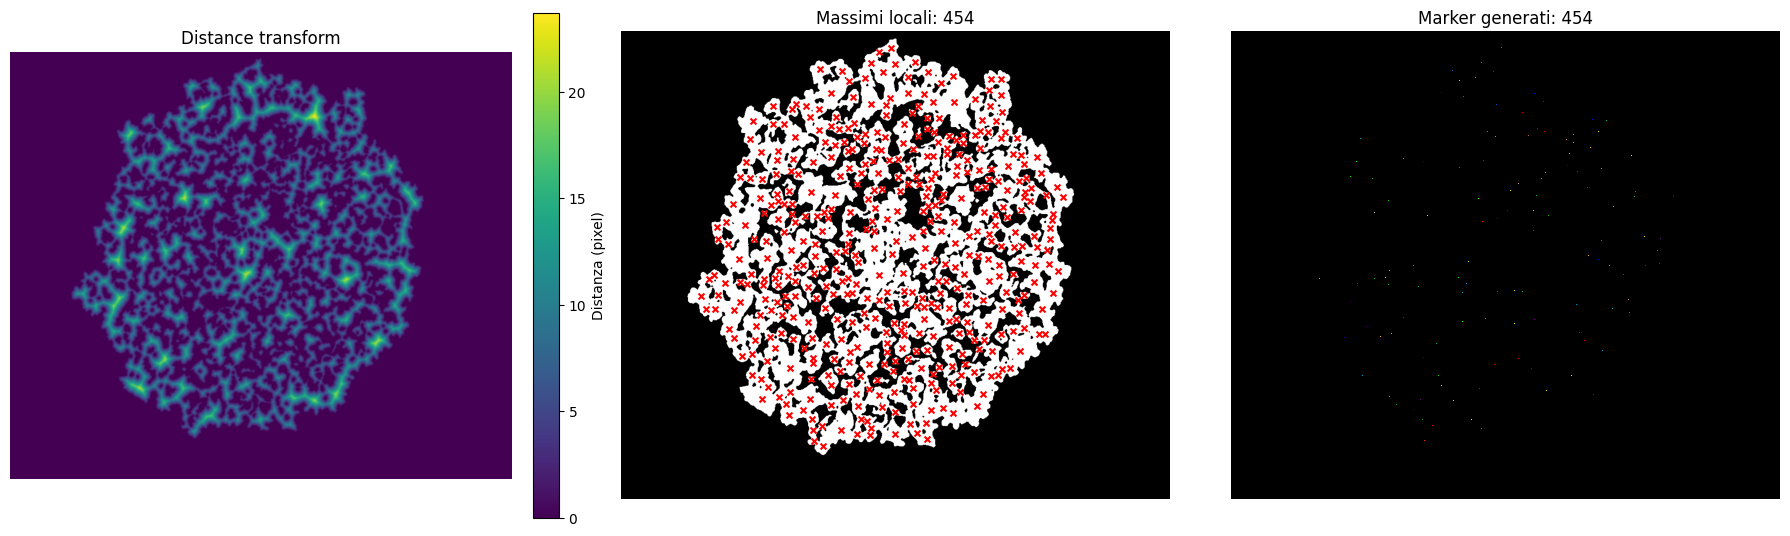

In [6]:
# ----------------------- 9. DISTANCE TRANSFORM + MAXIMI LOCALI -----------------------

distance = ndi.distance_transform_edt(initial_mask)



# Parametri principali regolabili:

PEAK_MIN_DISTANCE = 8             # distanza minima tra seed in pixel

PEAK_THRESHOLD_REL = 0.12     # altezza minima relativa dei massimi

MIN_PARTICLE_AREA = 35             # area minima finale in pixel

WATERSHED_COMPACTNESS = 0     # 0 = watershed standard



coords = feature.peak_local_max(

        distance,

        min_distance=PEAK_MIN_DISTANCE,

        threshold_rel=PEAK_THRESHOLD_REL,

        labels=initial_mask.astype(np.uint8),

        exclude_border=False

)



markers = np.zeros(distance.shape, dtype=np.int32)

for idx, (y, x) in enumerate(coords, start=1):

        markers[y, x] = idx



# Fallback se nessun massimo trovato.

if markers.max() == 0 and initial_mask.any():

        labels_cc, n_cc = ndi.label(initial_mask)

        markers = labels_cc.astype(np.int32)


# ----------------------- 10. VISUALIZZAZIONE DISTANCE TRANSFORM E MARKER -----------------------

print(f"Numero di massimi locali trovati: {len(coords)}")
print(f"Numero di marker generati: {markers.max()}")
print(f"Dimensioni della distance transform: {distance.shape}")
print(f"Valore massimo della distance transform: {distance.max():.2f} pixel")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Distance transform
im0 = axes[0].imshow(distance, cmap="viridis")
axes[0].set_title("Distance transform")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="Distanza (pixel)")

# 2. Massimi locali sulla maschera
axes[1].imshow(initial_mask, cmap="gray")
if len(coords) > 0:
    axes[1].scatter(
        coords[:, 1], coords[:, 0],
        s=18, c="red", marker="x"
    )
axes[1].set_title(f"Massimi locali: {len(coords)}")
axes[1].axis("off")

# 3. Marker numerati per regione
axes[2].imshow(markers, cmap="nipy_spectral", interpolation="nearest")
axes[2].set_title(f"Marker generati: {markers.max()}")
axes[2].axis("off")

plt.tight_layout()
plt.show()


# ***Watershed***


===== RISULTATI WATERSHED =====
Numero di particelle segmentate: 454
Dimensioni dell'immagine: (872, 1024)
Numero di pixel appartenenti alle particelle: 275572
Numero di pixel dello sfondo: 617356
Area media delle particelle: 606.99 pixel
Area minima delle particelle: 40 pixel
Area massima delle particelle: 3931 pixel


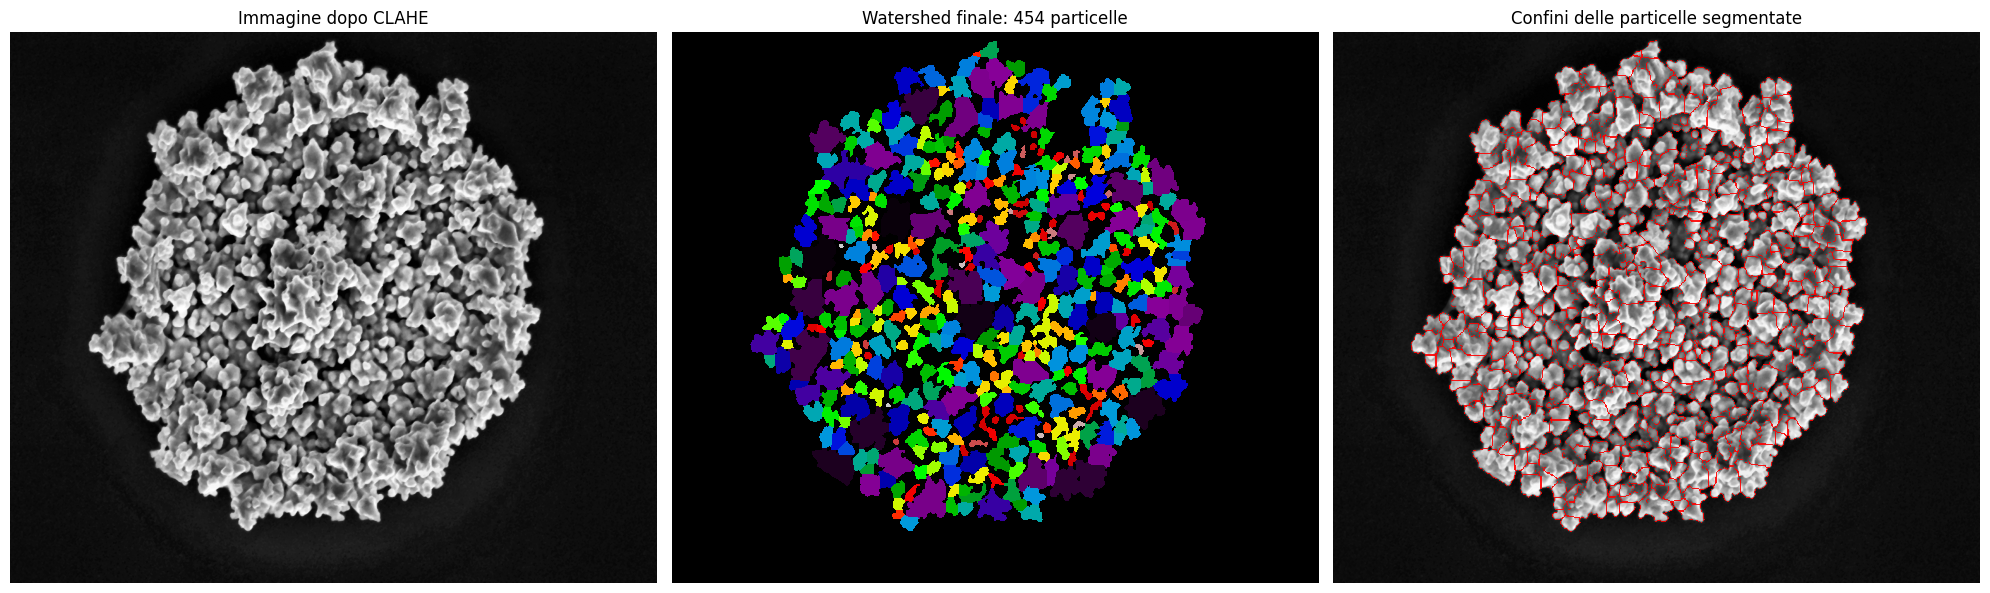

In [7]:
# ----------------------- 10. WATERSHED -----------------------
# Watershed sulla superficie negativa della distanza

labels = segmentation.watershed(
    -distance,
    markers=markers,
    mask=initial_mask,
    compactness=WATERSHED_COMPACTNESS
).astype(np.int32)


# ----------------------- 10.1 STAMPE RISULTATI -----------------------

n_particles = len(np.unique(labels[labels > 0]))
n_pixels = np.count_nonzero(labels)

print("===== RISULTATI WATERSHED =====")
print(f"Numero di particelle segmentate: {n_particles}")
print(f"Dimensioni dell'immagine: {labels.shape}")
print(f"Numero di pixel appartenenti alle particelle: {n_pixels}")
print(f"Numero di pixel dello sfondo: {labels.size - n_pixels}")

if n_particles > 0:
    areas = np.bincount(labels.ravel())[1:]
    print(f"Area media delle particelle: {areas.mean():.2f} pixel")
    print(f"Area minima delle particelle: {areas.min()} pixel")
    print(f"Area massima delle particelle: {areas.max()} pixel")
else:
    print("Nessuna particella trovata.")


# ----------------------- 10.2 VISUALIZZAZIONE FINALE -----------------------

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1. Immagine elaborata
axes[0].imshow(enhanced, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Immagine dopo CLAHE")
axes[0].axis("off")

# 2. Risultato finale del watershed
axes[1].imshow(labels, cmap="nipy_spectral", interpolation="nearest")
axes[1].set_title(f"Watershed finale: {n_particles} particelle")
axes[1].axis("off")

# 3. Confini delle particelle sull'immagine elaborata
axes[2].imshow(enhanced, cmap="gray", vmin=0, vmax=1)

boundaries = segmentation.find_boundaries(labels, mode="outer")
axes[2].imshow(
    np.ma.masked_where(~boundaries, boundaries),
    cmap="autumn",
    alpha=0.9,
    interpolation="nearest"
)

axes[2].set_title("Confini delle particelle segmentate")
axes[2].axis("off")

plt.tight_layout()
plt.show()


===== RISULTATI WATERSHED =====
Numero di particelle segmentate: 454
Dimensioni dell'immagine: (872, 1024)
Numero di pixel appartenenti alle particelle: 275572
Numero di pixel dello sfondo: 617356
Area media delle particelle: 606.99 pixel
Area minima delle particelle: 40 pixel
Area massima delle particelle: 3931 pixel


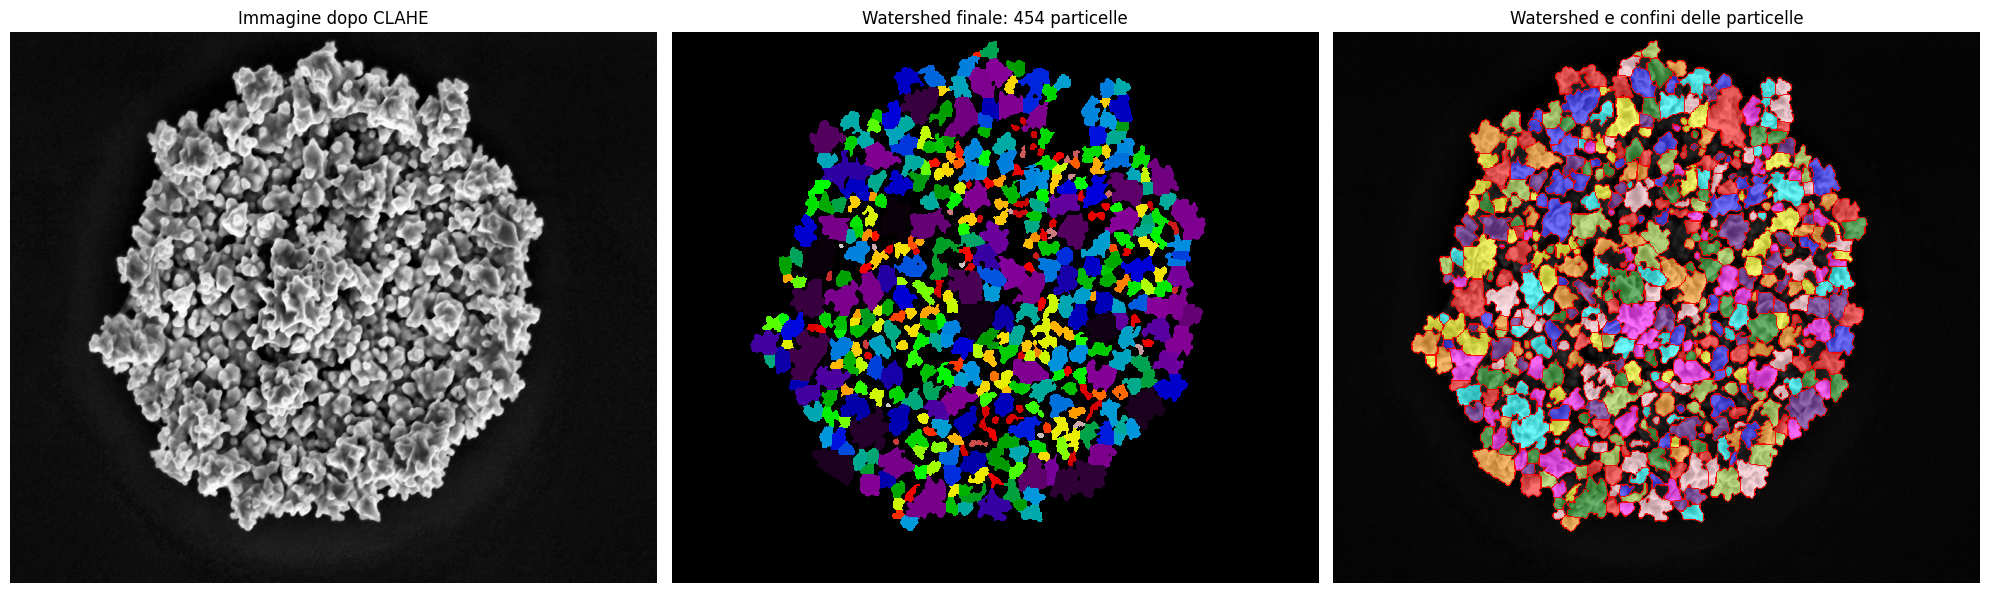

In [8]:
# ----------------------- 10. WATERSHED -----------------------
# Watershed sulla superficie negativa della distanza

labels = segmentation.watershed(
    -distance,
    markers=markers,
    mask=initial_mask,
    compactness=WATERSHED_COMPACTNESS
).astype(np.int32)


# ----------------------- 10.1 STAMPE RISULTATI -----------------------

n_particles = len(np.unique(labels[labels > 0]))
n_pixels = np.count_nonzero(labels)

print("===== RISULTATI WATERSHED =====")
print(f"Numero di particelle segmentate: {n_particles}")
print(f"Dimensioni dell'immagine: {labels.shape}")
print(f"Numero di pixel appartenenti alle particelle: {n_pixels}")
print(f"Numero di pixel dello sfondo: {labels.size - n_pixels}")

if n_particles > 0:
    areas = np.bincount(labels.ravel())[1:]
    print(f"Area media delle particelle: {areas.mean():.2f} pixel")
    print(f"Area minima delle particelle: {areas.min()} pixel")
    print(f"Area massima delle particelle: {areas.max()} pixel")
else:
    print("Nessuna particella trovata.")


# ----------------------- 10.2 VISUALIZZAZIONE FINALE -----------------------

# Etichette colorate sovrapposte all'immagine in scala di grigi.
# Le regioni con label 0 restano sullo sfondo.
watershed_final = color.label2rgb(
    labels,
    image=enhanced,
    bg_label=0,
    alpha=0.55
)

# Confini delle particelle
boundaries = segmentation.find_boundaries(
    labels,
    connectivity=1,
    mode="thick"
)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1. Immagine elaborata
axes[0].imshow(enhanced, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Immagine dopo CLAHE")
axes[0].axis("off")

# 2. Risultato finale del watershed
axes[1].imshow(
    labels,
    cmap="nipy_spectral",
    interpolation="nearest"
)
axes[1].set_title(f"Watershed finale: {n_particles} particelle")
axes[1].axis("off")

# 3. Overlay colorato con confini
axes[2].imshow(watershed_final)
axes[2].imshow(
    np.ma.masked_where(~boundaries, boundaries),
    cmap="autumn",
    alpha=0.9,
    interpolation="nearest"
)
axes[2].set_title("Watershed e confini delle particelle")
axes[2].axis("off")






plt.tight_layout()
plt.show()

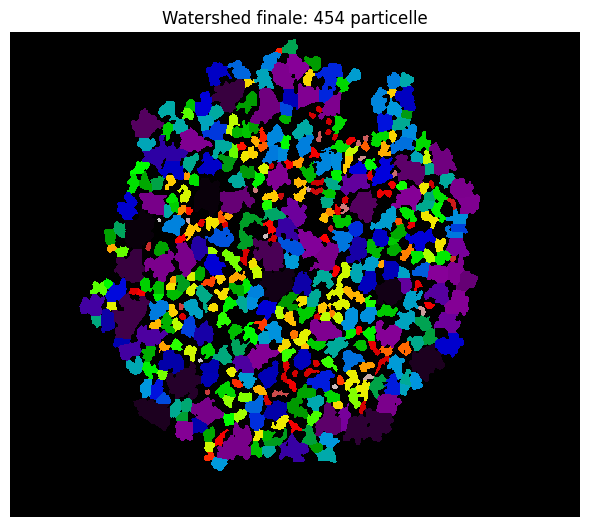

In [16]:
# ----------------------- 10.2 VISUALIZZAZIONE WATERSHED -----------------------

fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(labels, cmap="nipy_spectral", interpolation="nearest")
ax.set_title(f"Watershed finale: {n_particles} particelle")
ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
import numpy as np

particle_ids, areas = np.unique(labels[labels > 0], return_counts=True)

diameters_px = 2 * np.sqrt(areas / np.pi)

for particle_id, area, diameter in zip(particle_ids, areas, diameters_px):
    print(
        f"Particella {particle_id}: "
        f"area = {area} px², "
        f"diametro equivalente = {diameter:.2f} px"
    )

# Tabella dei risultati
particle_measurements = pd.DataFrame({
    "particella": particle_ids,
    "area_px2": areas,
    "diametro_equivalente_px": diameters_px
})

print(particle_measurements)

Particella 1: area = 3931 px², diametro equivalente = 70.75 px
Particella 2: area = 2377 px², diametro equivalente = 55.01 px
Particella 3: area = 2704 px², diametro equivalente = 58.68 px
Particella 4: area = 2617 px², diametro equivalente = 57.72 px
Particella 5: area = 1824 px², diametro equivalente = 48.19 px
Particella 6: area = 2535 px², diametro equivalente = 56.81 px
Particella 7: area = 2364 px², diametro equivalente = 54.86 px
Particella 8: area = 2661 px², diametro equivalente = 58.21 px
Particella 9: area = 1975 px², diametro equivalente = 50.15 px
Particella 10: area = 1726 px², diametro equivalente = 46.88 px
Particella 11: area = 2283 px², diametro equivalente = 53.91 px
Particella 12: area = 2266 px², diametro equivalente = 53.71 px
Particella 13: area = 1536 px², diametro equivalente = 44.22 px
Particella 14: area = 1747 px², diametro equivalente = 47.16 px
Particella 15: area = 2324 px², diametro equivalente = 54.40 px
Particella 16: area = 1848 px², diametro equivale

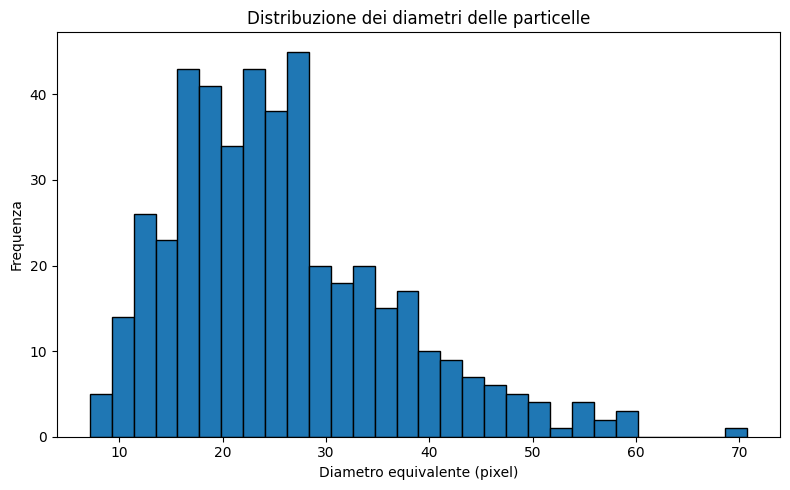

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(diameters_px, bins=30, edgecolor="black")

plt.xlabel("Diametro equivalente (pixel)")
plt.ylabel("Frequenza")
plt.title("Distribuzione dei diametri delle particelle")
plt.tight_layout()
plt.show()

In [19]:
import numpy as np

micron_per_pixel_x = 0.0125786
micron_per_pixel_y = 0.0125786

# Conversioni
areas_um2 = areas * micron_per_pixel_x * micron_per_pixel_y
diameters_um = diameters_px * micron_per_pixel_x  # pixel quadrati: calibrazione uguale su X e Y

print("===== MISURE DI TUTTE LE PARTICELLE =====")
print(f"Calibrazione: {micron_per_pixel_x} µm/pixel (X), "
      f"{micron_per_pixel_y} µm/pixel (Y)")
print(f"Numero di particelle: {len(particle_ids)}\n")

for particle_id, area_px2, diameter_px, area_um2, diameter_um in zip(
    particle_ids, areas, diameters_px, areas_um2, diameters_um
):
    print(
        f"Particella {particle_id}: "
        f"area = {area_px2} px² ({area_um2:.4f} µm²), "
        f"diametro equivalente = {diameter_px:.2f} px ({diameter_um:.4f} µm)"
    )

===== MISURE DI TUTTE LE PARTICELLE =====
Calibrazione: 0.0125786 µm/pixel (X), 0.0125786 µm/pixel (Y)
Numero di particelle: 454

Particella 1: area = 3931 px² (0.6220 µm²), diametro equivalente = 70.75 px (0.8899 µm)
Particella 2: area = 2377 px² (0.3761 µm²), diametro equivalente = 55.01 px (0.6920 µm)
Particella 3: area = 2704 px² (0.4278 µm²), diametro equivalente = 58.68 px (0.7381 µm)
Particella 4: area = 2617 px² (0.4141 µm²), diametro equivalente = 57.72 px (0.7261 µm)
Particella 5: area = 1824 px² (0.2886 µm²), diametro equivalente = 48.19 px (0.6062 µm)
Particella 6: area = 2535 px² (0.4011 µm²), diametro equivalente = 56.81 px (0.7146 µm)
Particella 7: area = 2364 px² (0.3740 µm²), diametro equivalente = 54.86 px (0.6901 µm)
Particella 8: area = 2661 px² (0.4210 µm²), diametro equivalente = 58.21 px (0.7322 µm)
Particella 9: area = 1975 px² (0.3125 µm²), diametro equivalente = 50.15 px (0.6308 µm)
Particella 10: area = 1726 px² (0.2731 µm²), diametro equivalente = 46.88 px (

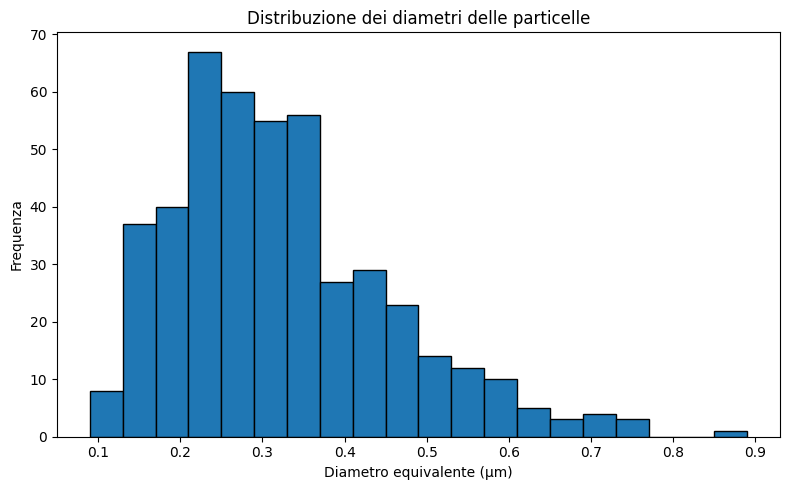

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(diameters_um, bins=20, edgecolor="black")

plt.xlabel("Diametro equivalente (µm)")
plt.ylabel("Frequenza")
plt.title("Distribuzione dei diametri delle particelle")
plt.tight_layout()
plt.show()

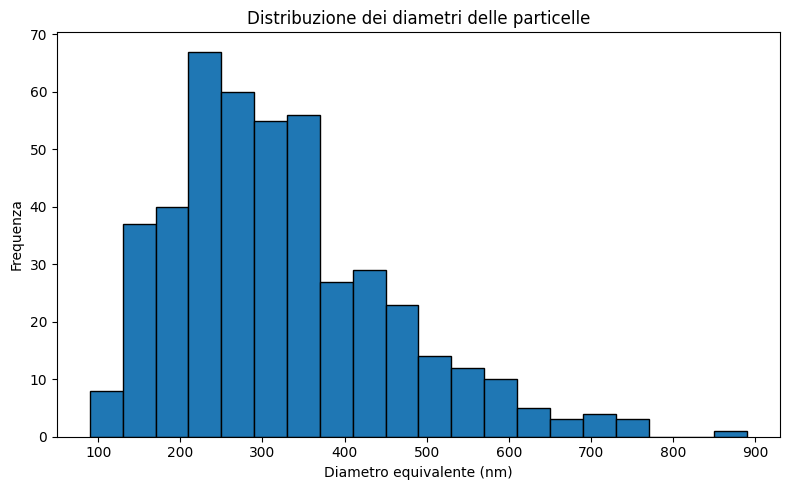

In [21]:
"""diameters_nm = diameters_um * 1000

plt.figure(figsize=(8, 5))
plt.hist(diameters_nm, bins=20, edgecolor="black")

plt.xlabel("Diametro equivalente (nm)")
plt.ylabel("Frequenza")
plt.title("Distribuzione dei diametri delle particelle")
plt.tight_layout()
plt.show()
"""
